# 05 · Agreement with reference flood maps and published estimates

References available as GIS layers (Sentinel Asia):
* **MBRSC**, Sentinel-1, 16 June 2022 — same scene as our 16 June map, so not independent of the sensor.
* **EOS-RS Flood Proxy Map**, ALOS-2 PALSAR-2 (L-band), 22 June 2022 — independent sensor; 4 days after our 18 June scene and 6 days before 28 June.
* **EOS-RS**, Sentinel-1, 18 May 2022 — the earlier May flood wave (checks the baseline choice).

Published areas: Irukumati et al. (2025), same district and dates, including the NRSC areas they used as reference.

Caveat: the reference products are rapid-mapping outputs with their own errors (they are usually conservative), so disagreement is not all our error.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, geopandas as gpd, rasterio, matplotlib.pyplot as plt
from scipy import stats
import config, classify as C

st = C.static(); district = st["district"]
REF = config.DATA_PROCESSED / "reference_nagaon.gpkg"
ref = {n: C.rasterize_gdf(gpd.read_file(REF, layer=n)).astype(bool) & district
       for n in ["mbrsc_s1_20220616", "eosrs_alos2_20220622", "eosrs_s1_20220518"]}
maps = {}
for date, orb in config.EVENT_DATES:
    with rasterio.open(config.OUT_RASTERS / f"flood_{date.replace('-', '')}_t{orb}.tif") as r:
        maps[(date, orb)] = r.read(1)
# June envelope: flooded on any date (observed on at least one date)
env = np.full(district.shape, 255, np.uint8)
anyobs = np.logical_or.reduce([m != 255 for m in maps.values()])
env[anyobs] = 0
env[np.logical_or.reduce([m == 1 for m in maps.values()])] = 1
for k in ref: print(k, round(ref[k].sum() * C.PIX_KM2, 1), "km2 in district")

mbrsc_s1_20220616 128.2 km2 in district
eosrs_alos2_20220622 144.0 km2 in district
eosrs_s1_20220518 94.6 km2 in district


## 1 · Pixel agreement (10 m)

In [2]:
pairs = [("mbrsc_s1_20220616", "2022-06-16 t41", maps[("2022-06-16", 41)]),
         ("eosrs_alos2_20220622", "2022-06-18 t77", maps[("2022-06-18", 77)]),
         ("eosrs_alos2_20220622", "2022-06-28 t41", maps[("2022-06-28", 41)]),
         ("eosrs_alos2_20220622", "June envelope (any date)", env)]
pix = pd.DataFrame([{"reference": r, "ours": lab, **C.agreement(cl, ref[r])} for r, lab, cl in pairs]).round(3)
pix.to_csv(config.OUT_TABLES / "validation_pixel.csv", index=False)
pix

,reference,ours,ours_km2,ref_km2,precision,recall,f1,iou,overall_accuracy,kappa
0,mbrsc_s1_20220616,2022-06-16 t41,303.131,128.096,0.330,0.781,0.464,0.302,0.904,0.420
1,eosrs_alos2_20220622,2022-06-18 t77,503.388,143.676,0.144,0.505,0.224,0.126,0.805,0.150
2,eosrs_alos2_20220622,2022-06-28 t41,559.049,135.041,0.122,0.504,0.196,0.109,0.767,0.116
3,eosrs_alos2_20220622,June envelope (any date),766.424,144.020,0.110,0.588,0.186,0.102,0.712,0.101


## 2 · Agreement at coarser scales (tolerates small geolocation and edge differences)

Flood fraction per cell, ours vs reference; Pearson r and mean absolute difference.

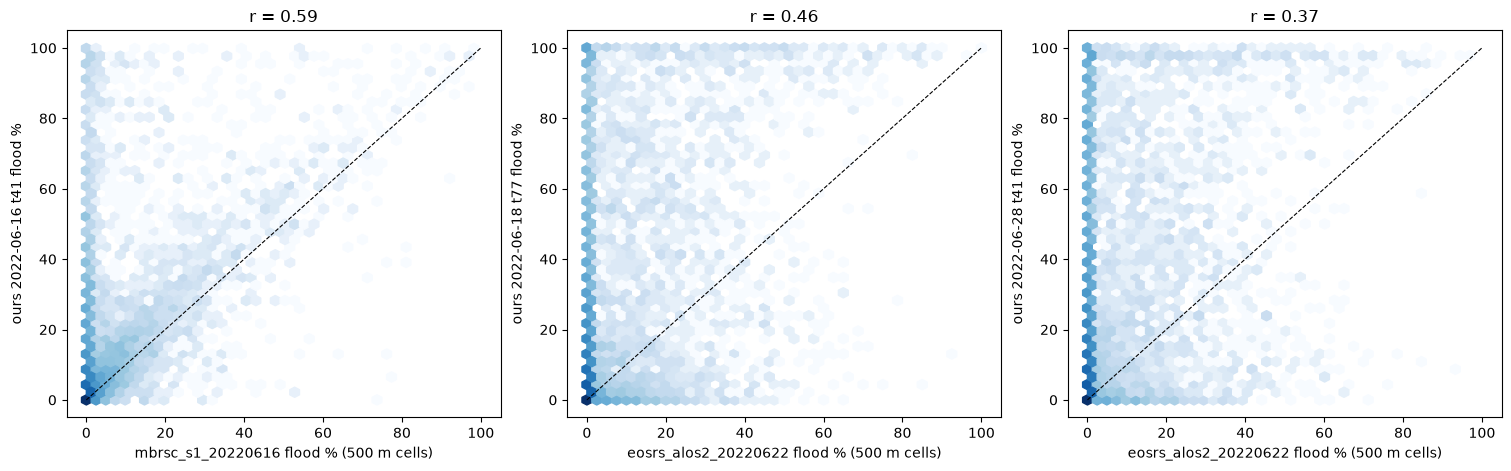

,reference,ours,cell_m,n_cells,pearson_r,mean_abs_diff_pct
0,mbrsc_s1_20220616,2022-06-16 t41,100,237918,0.567,9.228000
1,mbrsc_s1_20220616,2022-06-16 t41,500,9253,0.591,8.683000
2,mbrsc_s1_20220616,2022-06-16 t41,1000,2238,0.611,8.515000
3,eosrs_alos2_20220622,2022-06-18 t77,100,255118,0.278,18.872999
4,eosrs_alos2_20220622,2022-06-18 t77,500,9876,0.457,17.011000
5,eosrs_alos2_20220622,2022-06-18 t77,1000,2378,0.566,16.202000
6,eosrs_alos2_20220622,2022-06-28 t41,100,237731,0.225,22.643000
7,eosrs_alos2_20220622,2022-06-28 t41,500,9253,0.373,20.784000
8,eosrs_alos2_20220622,2022-06-28 t41,1000,2238,0.468,19.920000


In [3]:
def block_mean(a, k):
    H, W = (a.shape[0] // k) * k, (a.shape[1] // k) * k
    return a[:H, :W].reshape(H // k, k, W // k, k).mean(axis=(1, 3))

rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
for ax, (r, lab, cl) in zip(axes, pairs[:3]):
    ok = (cl != 255) & district
    for k in (10, 50, 100):  # 100 m, 500 m, 1 km
        valid = block_mean(ok.astype(np.float32), k) > 0.9
        fo = block_mean(((cl == 1) & ok).astype(np.float32), k)[valid]
        fr = block_mean((ref[r] & ok).astype(np.float32), k)[valid]
        rows.append({"reference": r, "ours": lab, "cell_m": k * 10, "n_cells": int(valid.sum()),
                     "pearson_r": stats.pearsonr(fo, fr)[0], "mean_abs_diff_pct": 100 * np.abs(fo - fr).mean()})
        if k == 50:
            ax.hexbin(fr * 100, fo * 100, gridsize=40, bins="log", cmap="Blues", mincnt=1)
            ax.plot([0, 100], [0, 100], "k--", lw=0.8)
            ax.set_xlabel(f"{r} flood % (500 m cells)"); ax.set_ylabel(f"ours {lab} flood %")
            ax.set_title(f"r = {rows[-1]['pearson_r']:.2f}")
fig.savefig(config.OUT_FIGURES / "validation_cell_scatter.png", dpi=150); plt.show()
cells = pd.DataFrame(rows).round(3)
cells.to_csv(config.OUT_TABLES / "validation_cells.csv", index=False)
cells

## 3 · Where do the maps disagree? (by land cover and by JRC water history)

Commission = ours only; omission = reference only. Land cover from WorldCover 2021.

In [4]:
WC = {10: "tree cover", 20: "shrubland", 30: "grassland", 40: "cropland", 50: "built-up",
      60: "bare", 80: "permanent water", 90: "herbaceous wetland"}
wc = np.nan_to_num(st["worldcover"], nan=0).astype(int)
occ = np.nan_to_num(st["occurrence"], nan=0)
recs = []
for r, lab, cl in pairs[:3]:
    ok = (cl != 255) & district
    ours, refm = (cl == 1) & ok, ref[r] & ok
    for name, m in [("agree", ours & refm), ("ours only", ours & ~refm), ("reference only", ~ours & refm)]:
        row = {"reference": r, "ours": lab, "set": name, "total_km2": m.sum() * C.PIX_KM2,
               "jrc_ever_water_pct": 100 * np.count_nonzero(m & (occ > 0)) / max(m.sum(), 1)}
        for code, cname in WC.items():
            row[cname] = np.count_nonzero(m & (wc == code)) * C.PIX_KM2
        recs.append(row)
dis = pd.DataFrame(recs).round(1)
dis.to_csv(config.OUT_TABLES / "validation_disagreement_landcover.csv", index=False)
dis

,reference,ours,set,total_km2,jrc_ever_water_pct,tree cover,shrubland,grassland,cropland,built-up,bare,permanent water,herbaceous wetland
0,mbrsc_s1_20220616,2022-06-16 t41,agree,100.0,40.3,0.6,0.0,1.4,97.8,0.0,0.1,0.1,0.2
1,mbrsc_s1_20220616,2022-06-16 t41,ours only,203.1,48.8,5.0,0.0,7.1,183.6,0.0,1.3,3.4,2.8
2,mbrsc_s1_20220616,2022-06-16 t41,reference only,28.0,23.0,0.1,0.0,0.4,27.4,0.0,0.0,0.0,0.1
3,eosrs_alos2_20220622,2022-06-18 t77,agree,72.5,75.0,1.7,0.0,2.6,67.0,0.0,0.2,0.5,0.6
4,eosrs_alos2_20220622,2022-06-18 t77,ours only,430.9,45.9,10.2,0.0,28.2,377.9,0.1,2.9,9.0,2.7
5,eosrs_alos2_20220622,2022-06-18 t77,reference only,71.2,11.4,36.0,0.0,1.9,28.5,2.1,0.3,1.4,0.9
6,eosrs_alos2_20220622,2022-06-28 t41,agree,68.1,71.7,1.7,0.0,1.8,63.4,0.0,0.1,0.2,0.9
7,eosrs_alos2_20220622,2022-06-28 t41,ours only,491.0,37.7,11.2,0.0,21.9,447.2,0.1,2.2,4.0,4.3
8,eosrs_alos2_20220622,2022-06-28 t41,reference only,66.9,9.7,35.1,0.0,1.7,26.1,2.1,0.3,1.1,0.6


## 4 · Sub-district totals

In [5]:
subs = gpd.read_file(config.DATA_PROCESSED / "nagaon_2022_subdistricts.geojson").reset_index(drop=True)
sub_id = C.rasterize_gdf(subs, values=range(1, len(subs) + 1)); n = len(subs) + 1
rows = []
for r, lab, cl in pairs[:3]:
    ok = (cl != 255) & district
    o = np.bincount(sub_id[(cl == 1) & ok], minlength=n)[1:] * C.PIX_KM2
    f = np.bincount(sub_id[ref[r] & ok], minlength=n)[1:] * C.PIX_KM2
    rho = stats.spearmanr(o, f)[0]
    for name, a, b in zip(subs.sdtname, o, f):
        rows.append({"reference": r, "ours": lab, "subdistrict": name, "ours_km2": a, "ref_km2": b, "spearman_rho_all": rho})
subcmp = pd.DataFrame(rows).round(2)
subcmp.to_csv(config.OUT_TABLES / "validation_subdistrict.csv", index=False)
subcmp.pivot_table(index="subdistrict", columns=["reference", "ours"], values=["ours_km2", "ref_km2"]).round(1)

ours_km2                                   \
reference   eosrs_alos2_20220622                mbrsc_s1_20220616   
ours              2022-06-18 t77 2022-06-28 t41    2022-06-16 t41   
subdistrict                                                         
Dhing                       25.1           30.6              21.2   
Kaliabor                    57.5           27.2              20.4   
Kampur                     171.2          131.0              84.4   
Nagaon                      74.7          116.5              54.3   
Raha                       124.2          166.7              85.1   
Rupahi                      18.4           35.0              11.4   
Samaguri                    32.2           52.1              26.3   

                         ref_km2                                   
reference   eosrs_alos2_20220622                mbrsc_s1_20220616  
ours              2022-06-18 t77 2022-06-28 t41    2022-06-16 t41  
subdistrict                                                        
Dhing                        0.0            0.0               0.0  
Kaliabor                    15.6            7.6               0.6  
Kampur                      66.2           65.8              57.3  
Nagaon                      27.0           27.0              18.7  
Raha                        16.6           16.4              31.1  
Rupahi                      12.2           12.2               1.7  
Samaguri                     6.0            6.0              18.7

In [6]:
subcmp.groupby(["reference", "ours"]).spearman_rho_all.first().round(2)

reference             ours          
eosrs_alos2_20220622  2022-06-18 t77    0.86
                      2022-06-28 t41    0.71
mbrsc_s1_20220616     2022-06-16 t41    0.82
Name: spearman_rho_all, dtype: float64

## 5 · Published estimates for the same district and dates

From Irukumati et al. (2025), Table 3 and text. The NRSC 30 June value is read from the table layout (its column is split in the PDF); treat it with care.

In [7]:
areas = pd.read_csv(config.OUT_TABLES / "flood_area_by_date.csv")
ours18 = areas.query("date == '2022-06-18'").flood_km2.iloc[0]
ours30 = areas.query("date == '2022-06-30'").flood_km2.iloc[0]
pub = pd.DataFrame([
    ("NRSC reference (as cited by Irukumati et al.)", 413.28, 597.32),
    ("Irukumati et al.: Random Forest, VV", 395.56, 565.27),
    ("Irukumati et al.: Random Forest, VH", 383.19, 583.21),
    ("Irukumati et al.: Random Forest, VV+VH", 400.29, 592.12),
    ("Irukumati et al.: K-means, VV", 413.28, 613.23),
    ("Irukumati et al.: K-means, VH", 389.24, 592.64),
    ("Irukumati et al.: K-means, VV+VH", 401.78, 551.93),
    ("This study (VH change detection, Otsu)", ours18, ours30),
], columns=["source", "18 Jun 2022 (km2)", "30 Jun 2022 (km2)"])
pub.to_csv(config.OUT_TABLES / "validation_published_areas.csv", index=False)
pub.round(1)

,source,18 Jun 2022 (km2),30 Jun 2022 (km2)
0,NRSC reference (as cited by Irukumati et al.),413.3,597.3
1,"Irukumati et al.: Random Forest, VV",395.6,565.3
2,"Irukumati et al.: Random Forest, VH",383.2,583.2
3,"Irukumati et al.: Random Forest, VV+VH",400.3,592.1
4,"Irukumati et al.: K-means, VV",413.3,613.2
5,"Irukumati et al.: K-means, VH",389.2,592.6
6,"Irukumati et al.: K-means, VV+VH",401.8,551.9
7,"This study (VH change detection, Otsu)",503.4,600.1


## 6 · May flood wave and baseline choice

Nagaon flooded in mid-May 2022. Our baseline uses January–mid-April scenes only. How much of the 18 May flood area reappears in June, and how much early-June flood is residual May water?

In [8]:
may = ref["eosrs_s1_20220518"]
rows = []
for (date, orb), cl in maps.items():
    ok = cl != 255
    rows.append({"date": date, "track": orb,
                 "flood_km2": np.count_nonzero(cl == 1) * C.PIX_KM2,
                 "of_which_in_may_flood_km2": np.count_nonzero((cl == 1) & may) * C.PIX_KM2,
                 "may_flood_reflooded_pct": 100 * np.count_nonzero((cl == 1) & may) / max(np.count_nonzero(may & ok), 1)})
mayc = pd.DataFrame(rows).round(1)
mayc.to_csv(config.OUT_TABLES / "validation_may_overlap.csv", index=False)
mayc

,date,track,flood_km2,of_which_in_may_flood_km2,may_flood_reflooded_pct
0,2022-06-04,41,142.8,11.6,14.9
1,2022-06-06,77,124.4,13.6,14.4
2,2022-06-16,41,303.1,27.8,35.8
3,2022-06-18,77,503.4,54.1,57.3
4,2022-06-28,41,559.0,39.1,50.4
5,2022-06-30,77,600.1,51.6,54.7
